In [46]:
#notebook to create a table of sky subtraction quality metrics from an RSS file of sky subtracted spectra

In [47]:
#need to read in an RSS file, get flux, sky, ivar, wave
#for sky lines, can sum over flux in sky, then flux in flux (sky sub) to find frac that was removed
#measure cont
#for science lines areas, could fit gaussians to sky lines in sky, use as template to see how much sky was removed
#for science lines aread, come up with a way to convert sky line residual into an uncertainty on the sci line
#relate sky line residual with ivar (assuming ivar is correct)
#knox's method which says, flux-sky line residual flux in the shape of the sky (after background removal), frac error- flux/skyflux
#any other metrics for now?
#faintness limit for detecting science line
#sky line and cont metrics can be same lines/areas as before (no need to change at this point)
#then need to save all metrics per spectrum in a nice table

In [48]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits, ascii
from astropy.table import Table,vstack
from scipy.optimize import bisect
from astropy.stats import sigma_clip
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
import astropy.units as u
from pathlib import Path


Science lines affected by sky:
    [OI] 6300, 6363 Å – tracers of shocks and ionization fronts

    [NI] 5198, 5200 Å – also tracers of shocks and ionization fronts; useful for density diagnostics and continuum fluorescence

    [OII] 7320, 7330 Å – auroral lines sensitive to electron temperature

    HeI 7281 Å – singlet line sensitive to deviations from Case B and to temperature

    HI 8863, 9015, 9229, 9545 Å – Paschen lines useful for reddening maps

    [SIII] 9069, 9531 Å – critical for determining temperature and S++ abundance

    [Cl II] 9123 Å – ionic abundance of Cl+

    [Cl IV] 8045 Å – ionic abundance of Cl³⁺

    [FeII] 8617 Å – ionic abundance of Fe⁺

    [CI] 8727 Å – recombination/auroral line of neutral carbon

In [49]:
#RSS file input, using old summary file as example

#input_XSframe = 'XSframe_3500_25000_1.fits' # from the SkySprint directory but based on old v1.1.0 data
# https://data.sdss5.org/sas/sdsswork/users/u6046038/lvm/SkySprint/XSframe_3500_25000_1.fits

input_XSframe = 'XSframe_DR20.fits' # used by Amy, I don't find this anywhere?

#input_XSframe = 'XSFrame_1.1.1_3469_31300_1_50.fits'
out_dir = input_XSframe[:input_XSframe.find('fits')-1]
# https://data.sdss5.org/sas/sdsswork/users/u6046038/lvm/MedCombined/XSFrame_1.1.1_3469_31300_1_50.fits

fits.info(input_XSframe)

with fits.open(input_XSframe) as hdul:
    wave=hdul['WAVE'].data
    flux=hdul['FLUX'].data
    sky=hdul['SKY'].data
    ivar=hdul['ivar'].data
    drpall = Table(hdul['DRP_ALL'].data)

Filename: XSframe_DR20.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  WAVE          1 ImageHDU         7   (12401,)   float32   
  2  FLUX          1 ImageHDU        20   (12401, 162)   float32   
  3  SKY           1 ImageHDU        20   (12401, 162)   float32   
  4  IVAR          1 ImageHDU        20   (12401, 162)   float32   
  5  SKYE_FLUX     1 ImageHDU        20   (12401, 162)   float32   
  6  SKYW_FLUX     1 ImageHDU        20   (12401, 162)   float32   
  7  DRP_ALL       1 BinTableHDU    159   162R x 71C   [6A, K, K, K, D, K, K, K, 5A, K, 15A, 23A, D, D, D, D, D, D, D, D, D, 3A, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, 13A, D, D, D, D, D, D, D, D, D, D, 13A, D, D, D, D, D, D, D, D, D, D, 23A, 77A, 65A, K, D, D, D, 7A, D, D, D, D]   


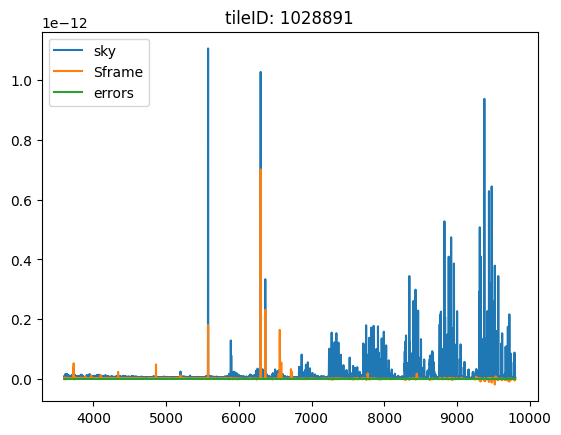

In [50]:
#test plots to make sure wave, sky, flux, and ivar look ok
expID = 50
exp = drpall[expID]

plt.plot(wave,sky[expID],label='sky',zorder=1)
plt.plot(wave,flux[expID],label='Sframe',zorder=2)
plt.plot(wave,1/np.sqrt(ivar[expID]),label='errors',zorder=3)
plt.title(f"tileID: {exp['tileid']}")
#plt.ylim(-0.1e-12,0.5e-12)
plt.legend()

In [51]:
#names of sky lines and cont regions
sky_list=['[OI]5577', '[OI]6300', '[OH]6865', '[Na]5891', 'O2', 'AirglowCont', 'Bcont', 'Rcont', 'Zcont']
#lrangelist=[(5574, 5580), (6298,6304), (6862,6868), (5888, 5898), (8630, 8670), (5420, 5440), (4195, 4220), (6420, 6440), (9130, 9145)] # original from Amy
lrangelist=[(5575, 5580), (6298,6302), (6861,6866), (5887, 5898), (8610, 8710), (5420, 5440), (4195, 4220), (6425, 6445), (9130, 9145)]
#extened range around the line for background cont subtraction where -999 means no cont subtraction done
#crangelist=[(5571, 5583), (6295, 6307), (6859, 6871), (5885, 5901), (-999, -999), (-999, -999), (-999, -999), (-999, -999), (-999, -999)] # original from Amy
crangelist=[(5571, 5583), (6289, 6305), (6853, 6868), (5880, 5901), (8600, 8724), (-999, -999), (-999, -999), (-999, -999), (-999, -999)]

#names of the science lines of interest
sci_lines=['[NI]5198','[NI]5200','[OII]7320','[OII]7330','HeI7281','HI8863','HI9015','HI9229','HI9545','[SIII]9069','[SIII]9531','[ClII]9123','[ClIV]8045','[FeII]8617','[CI]8727']
#wave location of those science lines
sci_lines_wave=[5198, 5200, 7320, 7330, 7281, 8863, 9015, 9229, 9545, 9069, 9531, 9123, 8045, 8617, 8727]
#OH and O2 should check wavelengths

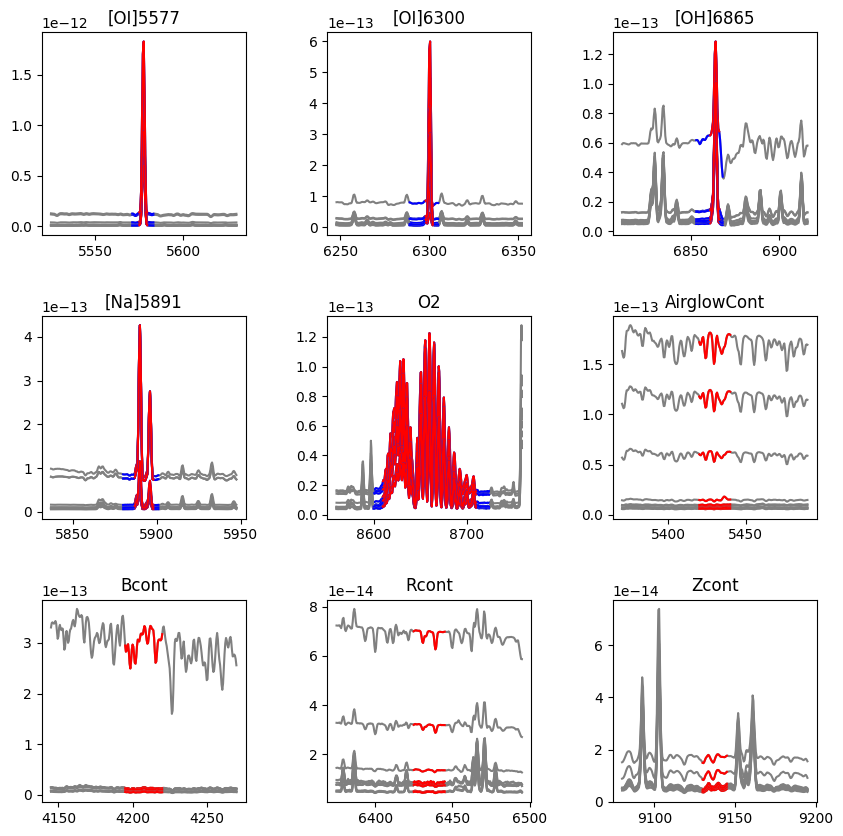

In [52]:
# Do some plots & checks of the selected line regions and continuum regions

fig,axs = plt.subplots(nrows=3, ncols=3, figsize=(10, 10),gridspec_kw={'wspace': 0.4, 'hspace': 0.4})
axsF = axs.flatten()

for which_line,nn in enumerate(sky_list):
    
    sub = (wave>=lrangelist[which_line][0]-50) & (wave<=lrangelist[which_line][1]+50) # line range selection
    sub_line = (wave>=lrangelist[which_line][0]) & (wave<=lrangelist[which_line][1]) # line range selection
    sub_cont = (wave>=crangelist[which_line][0]) & (wave<=crangelist[which_line][1]) # line range selection
    
    # 10 randomly selected spectra    
    for ii in np.random.randint(0, len(drpall)-1, size=10): #np.arange(100,110):
        axsF[which_line].plot(wave[sub], flux[ii,:][sub]+sky[ii,:][sub],label='flux+sky',color='grey') # spectrum    
        axsF[which_line].plot(wave[sub_cont], flux[ii,:][sub_cont]+sky[ii,:][sub_cont],label='flux+sky',color='blue') # cont
        axsF[which_line].plot(wave[sub_line], flux[ii,:][sub_line]+sky[ii,:][sub_line],label='flux+sky',color='red')  # line
    
    axsF[which_line].set_title(sky_list[which_line])

out_path = Path('sky_lines_list.png')
# Make sure the directory exists
out_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out_path)


In [53]:
#calculate sky line residual flux and sky line residual flux over sky line flux
#sky line residual flux over error
#for a single median exposure

#loops over all the sky lines/regions to get metrics for a given flux, sky, ivar
def sky_line_metrics(wave, flux, sky, ivar, sky_line_list, lrangelist, crangelist):
    resid_med_list = [] #median flux of the sky line residual
    sky_med_list = [] #median of sky flux (before sky subtraction)
    resid_sky_list = [] #residual flux over sky flux (like Knox's frac_error)

    for j in range(len(sky_list)):
        wvl, wvc = line_windows(lrangelist[j], crangelist[j], wave)
        resid_med, sky_med, resid_sky = line_stats(flux, sky, ivar, wvl, wvc)
        resid_med_list.append(resid_med)
        sky_med_list.append(sky_med)
        resid_sky_list.append(resid_sky)
    
    return resid_med_list, sky_med_list, resid_sky_list

#converts lrange and crange into wavelengths for each
def line_windows(lrange, crange, wave):
    wave_line = (wave>=lrange[0]) & (wave<=lrange[1]) # line range selection
    #ignores cont if crange is -999, and sets to -999
    if crange[0] == -999:
        wave_cont = [-999]
    else:
        wave_cont = ((wave>=crange[0]) & (wave<lrange[0])) | ((wave>lrange[1]) & (wave<=crange[1])) # cont range selection
    return wave_line, wave_cont

#calculates the sky line/region metrics
def line_stats(flux, sky, ivar, wave_line, wave_cont):
    #subtracting the average background cont if not -999
    if wave_cont[0] == -999:
        norm_line_flux = flux[wave_line]
        norm_line_sky = sky[wave_line]
    else:
        norm_line_flux = flux[wave_line]-np.nanmedian(flux[wave_cont])
        norm_line_sky = sky[wave_line]-np.nanmedian(sky[wave_cont])
        
    resid_med = np.nanmedian(norm_line_flux)
    sky_med = np.nanmedian(norm_line_sky)
    resid_sky = np.nanmedian(norm_line_flux / norm_line_sky)
    return resid_med, sky_med, resid_sky

In [54]:
resid_med_list, sky_med_list, resid_sky_list = sky_line_metrics(wave, flux[100], sky[100], ivar[100], sky_list, lrangelist, crangelist)

In [55]:
#testing if the line stats work, and looks ok!
for j in range(len(sky_list)):
    print(sky_list[j], resid_med_list[j], sky_med_list[j], resid_sky_list[j])

[OI]5577 -1.2339366e-14 2.420828e-13 -0.04810749
[OI]6300 -7.402422e-15 9.801265e-14 -0.09300391
[OH]6865 6.5566676e-17 1.1985748e-14 0.0018287919
[Na]5891 9.927941e-18 1.0813882e-14 -0.012391404
O2 -6.6798453e-16 1.8928308e-14 -0.030811902
AirglowCont -2.7248325e-16 7.106958e-15 -0.03899532
Bcont -4.8076627e-16 7.607422e-15 -0.060866103
Rcont -2.1834224e-16 6.1947212e-15 -0.035443474
Zcont -2.2770805e-16 5.108113e-15 -0.04819527


In [56]:
#need to loop over all median spectra/expnums and print to nice table...

In [57]:
def run_one_expnum(wave, flux, sky, ivar, drpall, sky_list, lrangelist, crangelist):
    
    resid_med_list, sky_med_list, resid_sky_list = sky_line_metrics(wave, flux, sky, ivar, sky_list, lrangelist, crangelist)

    row = []
    row.append(drpall["expnum"])
    row.append(drpall["sci_amass"])
    row.append(drpall["moon_alt"])
    row.append(drpall["moon_fli"])
    row.append(drpall["sci_moon_sep"])
    for j in range(len(sky_list)):
        row.append(resid_med_list[j])
        row.append(sky_med_list[j])
        row.append(resid_sky_list[j])
    return row

def run_RSS(wave, flux, sky, ivar, drpall, sky_list, lrangelist, crangelist):

    column_names = []
    column_names.append("expnum")
    column_names.append("sci_amass")
    column_names.append("moon_alt")
    column_names.append("moon_fli")
    column_names.append("sci_moon_sep")
    for j in range(len(sky_list)):
        column_names.append(f"{sky_list[j]}_resid_med")
        column_names.append(f"{sky_list[j]}_sky_med")
        column_names.append(f"{sky_list[j]}_resid_sky")

    metrics_tab = Table(names=column_names)

    #here loop over all expnums
    for i in range(flux.shape[0]):
        new_row = run_one_expnum(wave, flux[i], sky[i], ivar[i], drpall[i], sky_list, lrangelist, crangelist)
        metrics_tab.add_row(new_row)

    return metrics_tab

In [66]:
tab=run_RSS(wave, flux, sky, ivar, drpall, sky_list, lrangelist, crangelist)

In [67]:
tab

expnum,sci_amass,moon_alt,moon_fli,sci_moon_sep,[OI]5577_resid_med,[OI]5577_sky_med,[OI]5577_resid_sky,[OI]6300_resid_med,[OI]6300_sky_med,[OI]6300_resid_sky,[OH]6865_resid_med,[OH]6865_sky_med,[OH]6865_resid_sky,[Na]5891_resid_med,[Na]5891_sky_med,[Na]5891_resid_sky,O2_resid_med,O2_sky_med,O2_resid_sky,AirglowCont_resid_med,AirglowCont_sky_med,AirglowCont_resid_sky,Bcont_resid_med,Bcont_sky_med,Bcont_resid_sky,Rcont_resid_med,Rcont_sky_med,Rcont_resid_sky,Zcont_resid_med,Zcont_sky_med,Zcont_resid_sky
float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
3728.0,1.033,23.0426,0.5748,81.0249,6.25758041168439e-15,1.1940401195998512e-13,0.06283207982778549,1.7775062631096746e-14,6.915101087232034e-14,0.31719663739204407,3.1364420367898944e-16,1.451838188516394e-14,0.012314829975366592,-1.6203235237579965e-15,1.543875941532099e-14,-0.1153663918375969,-3.398720230253472e-16,9.380800105348967e-15,-0.02638404257595539,1.451441565338842e-15,1.4406947924689058e-14,0.10420601814985275,-3.773126792390002e-16,2.778094086426739e-14,-0.013332834467291832,2.605068887521914e-16,8.357133683537833e-15,0.02956087701022625,4.1161605776492128e-16,4.764981303680225e-15,0.08912623673677444
4168.0,1.637,44.8246,0.9756,86.473,2.4552293520756913e-14,2.2869946496480165e-13,0.10619448125362396,-8.961565383270188e-15,1.143746962374223e-13,-0.05774946138262749,2.769499158407655e-16,1.217408945462968e-14,0.03061358444392681,6.513688446583253e-15,1.3477385169251982e-14,0.18402963876724243,1.5544867232623535e-15,1.4849133004473693e-14,0.24710935354232788,-8.058115806564015e-15,1.6842435649269683e-13,-0.04878808557987213,-1.6089480618587844e-14,4.0091524934962597e-13,-0.04014849290251732,-3.018054835790562e-15,6.54093546361735e-14,-0.046552084386348724,-7.399511479415301e-16,1.599041164507698e-14,-0.05480027571320534
4171.0,1.234,26.3792,0.9738,86.1156,9.285682540537046e-15,8.791886896243259e-14,0.10648934543132782,3.400392082708939e-14,7.517899876848672e-14,0.47818073630332947,-2.568817994961798e-16,2.404019095337412e-14,-0.005351676605641842,5.548118744074871e-16,2.019912693053752e-14,0.0346207432448864,-4.658918379123883e-16,1.4644115455854367e-14,-0.043633460998535156,-5.453962138141609e-15,1.2793605964119686e-13,-0.043644972145557404,-1.5142631614763202e-14,3.194780865637542e-13,-0.04820691794157028,-4.456355955502174e-15,8.372356220852709e-14,-0.05408484488725662,-2.493821909570139e-15,3.415084377398833e-14,-0.07456019520759583
5355.0,1.682,-28.6077,0.3355,147.4525,3.2332548639303627e-14,1.143429562188228e-13,0.2941474914550781,1.2118170033517846e-14,6.342784641694826e-14,0.216987743973732,9.201424785141871e-17,1.0585757835893887e-14,0.0041360449977219105,7.319207462059673e-16,1.2646544103817395e-14,0.08455529063940048,1.1495973511782727e-15,1.1008238388226545e-14,0.133371502161026,-1.4813719509861056e-16,6.700892045288873e-15,-0.02321462519466877,2.12714814943711e-16,6.703351405451226e-15,0.0324329249560833,-4.0508429554106775e-16,6.5588590195944305e-15,-0.06120433658361435,-4.252967780636011e-16,4.281660492328658e-15,-0.09377984702587128
5511.0,2.072,33.695,0.7561,92.2859,4.325645473323564e-14,1.2000793967511386e-13,0.3769213557243347,9.604499812652934e-14,5.535966108270729e-14,2.0439231395721436,5.5632683518529874e-15,1.0761787375959328e-14,0.5169464945793152,-6.404212826282424e-16,9.281167007895233e-15,-0.00474733579903841,9.521582063380316e-16,1.0083631622563854e-14,0.09077242761850357,3.8455051859856426e-14,4.250752853006412e-14,0.8986960649490356,2.883245942345014e-14,9.942440208805803e-14,0.2918294668197632,3.818813144938586e-14,2.4208225349450427e-14,1.5705217123031616,2.2076690654607503e-14,6.864817484538051e-15,3.1083269119262695
5512.0,2.03,29.6356,0.7573,92.2832,4.0810992687481326e-14,1.316831436644697e-13,0.3295997977256775,8.250029755489316e-

In [68]:
# save the table

out_path = Path('drpqa_metrics_dr20.dat')
# Make sure the directory exists
out_path.parent.mkdir(parents=True, exist_ok=True)
ascii.write(tab, out_path, overwrite=True, format='fixed_width')

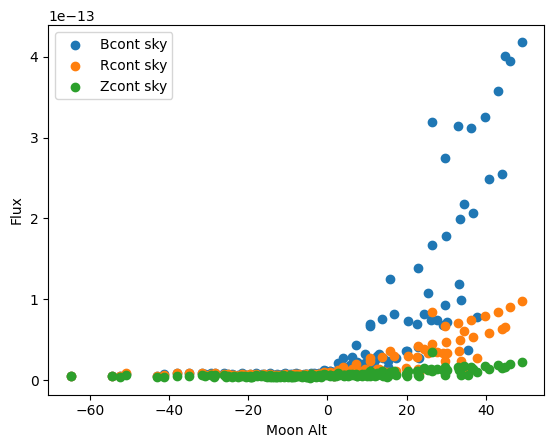

In [84]:
plt.scatter(tab['moon_alt'], tab['Bcont_sky_med'], label='Bcont sky')
plt.scatter(tab['moon_alt'], tab['Rcont_sky_med'], label='Rcont sky')
plt.scatter(tab['moon_alt'], tab['Zcont_sky_med'], label='Zcont sky')
plt.xlabel('Moon Alt')
plt.ylabel('Flux')
plt.legend()

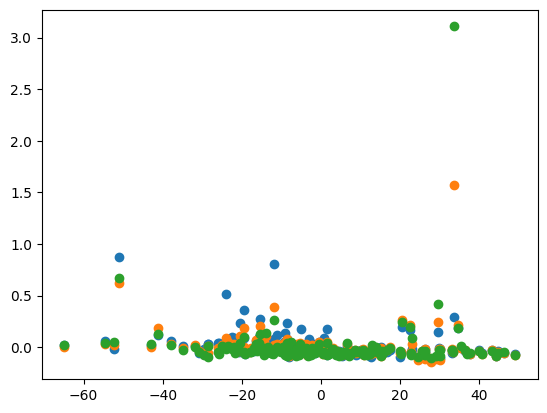

In [75]:
plt.scatter(tab['moon_alt'], tab['Bcont_resid_sky'])
plt.scatter(tab['moon_alt'], tab['Rcont_resid_sky'])
plt.scatter(tab['moon_alt'], tab['Zcont_resid_sky'])

In [77]:
tab['expnum'][tab['Zcont_resid_sky']>2]

5511.0


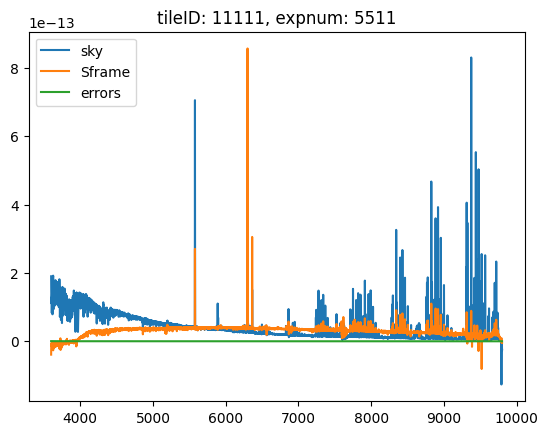

In [81]:
expID = 4
exp = drpall[expID]

plt.plot(wave,sky[expID],label='sky',zorder=1)
plt.plot(wave,flux[expID],label='Sframe',zorder=2)
plt.plot(wave,1/np.sqrt(ivar[expID]),label='errors',zorder=3)
plt.title(f"tileID: {exp['tileid']}, expnum: {exp['expnum']}")
#plt.ylim(-0.1e-12,0.5e-12)
plt.legend()

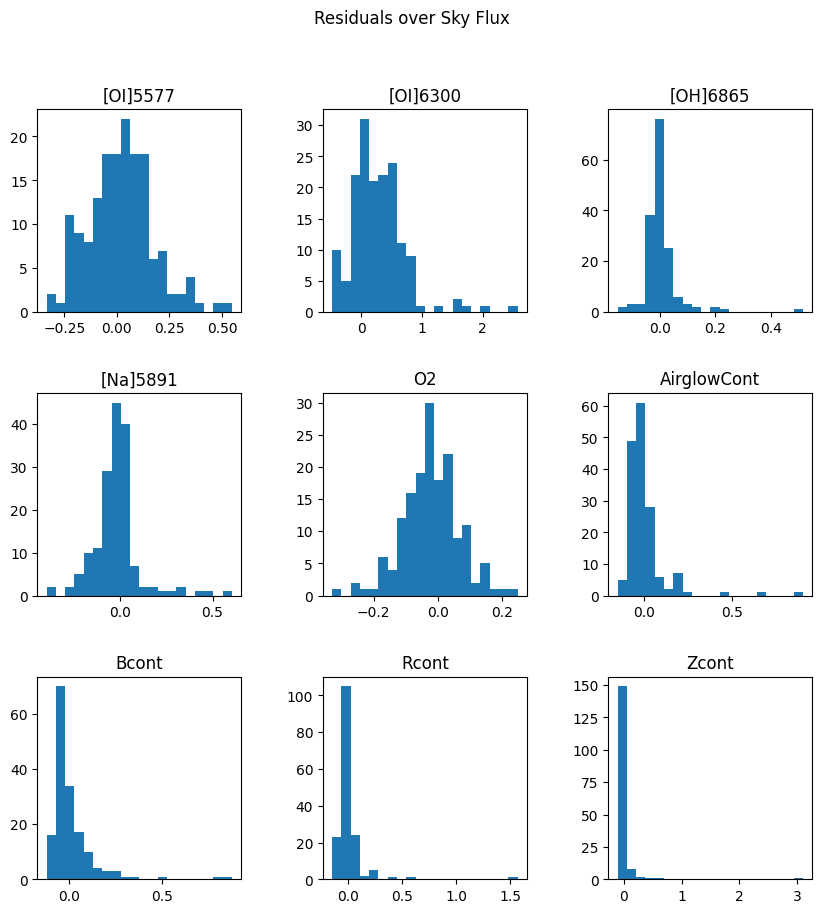

In [101]:
fig,axs = plt.subplots(nrows=3, ncols=3, figsize=(10, 10),gridspec_kw={'wspace': 0.4, 'hspace': 0.4})
axsF = axs.flatten()

plt.suptitle('Residuals over Sky Flux')

for which_line,nn in enumerate(sky_list):
    
    axsF[which_line].hist(tab[f"{sky_list[which_line]}_resid_sky"], bins=20)
    
    axsF[which_line].set_title(sky_list[which_line])
